# Step 7 — train on the PHQ-9 total score instead of the 0/1 label (paper1 variables and split)

**Question:** with the same 86 variables (re-encoded, step 6), people and 10-fold split as Dang et al. (2024), does training on the PHQ-9 total (0–27) rank PHQ-9 ≥ 10 better than training on the label? PHQ-9 is only the training target; the evaluation is unchanged (AUROC of PHQ-9 ≥ 10 per test fold). Variants fixed before running; all are reported.

**Targets**

- **squared:** regression on the total, squared error
- **poisson:** regression on the total, Poisson deviance (the total is skewed, most people 0–4)
- **multicut:** one binary model per cut-off (≥ 5, 10, 15, 20); score = sum of the four probabilities

**Models per target:** linear (L2; ridge / Poisson GLM / logistic regression on step 1's design matrix; step 6's elastic net chose l1_ratio = 0 in all 10 folds, so only the L2 strength is tuned) and XGBoost (step 1's settings, number of trees by early stopping on the inner fold's loss).

**Tuning:** inner 3-fold split of the training folds (as step 6), chosen by inner AUROC of PHQ-9 ≥ 10.
**Ensemble:** rank average within each test fold of **binary** (step 6's three label-trained models, re-encoded table) and **all** (those three + the six models here).

**Inputs** (with `RUN`): `PAPER1_REPRO`, `PAPER1_CSV` as in step 6; run step 6 first (it writes the re-encoded table and the label-trained predictions).
**Output:** `$NHANES_WORK/modeling/step7_phq9_target/` (`metrics.csv`, `predictions.csv.gz`, `chosen_params.json`, `report.txt`)

`RUN = True` retrains (a few hours); `QUICK = True` with it runs fold 0 only. `RUN = False` only shows the saved results.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS, THREADS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step7_phq9_target
QUICK = False  # with RUN: fold 0 only
PAPER1_REPRO = os.environ.get("PAPER1_REPRO")  # folder with build_dataset.py of the paper1 reproduction
PAPER1_CSV = os.environ.get("PAPER1_CSV")      # its FullData_rm_dl_bt.csv
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step7_phq9_target"
STEP6 = RESULTS / "step6_paper1_recoded"

## Models

In [2]:
if RUN:
    import xgboost as xgb
    from joblib import Parallel, delayed
    from scipy.stats import rankdata
    from sklearn.linear_model import LogisticRegression, PoissonRegressor, Ridge
    from sklearn.metrics import average_precision_score, roc_auc_score

    from nhanes.loco import NOT_FEATURES, SEED, XGB_GRID, grid, logreg_matrix
    from nhanes.paper1 import frames, phq9_totals

    CUTS = [5, 10, 15, 20]
    LINEAR_GRID = {"squared": [1.0, 10.0, 100.0, 1000.0],     # ridge alpha
                   "poisson": [1e-4, 1e-3, 1e-2, 1e-1],       # Poisson GLM alpha
                   "multicut": [0.003, 0.01, 0.03, 0.1]}      # logistic regression C
    XGB_OBJ = {"squared": "reg:squarederror", "poisson": "count:poisson", "multicut": "binary:logistic"}
    XGB_BASE = dict(learning_rate=0.05, n_estimators=2000, subsample=0.8, colsample_bytree=0.5, tree_method="hist",
                    early_stopping_rounds=100, n_jobs=THREADS, random_state=SEED)

    # ---------------- linear ----------------
    def linear_score(target, A, phq, B, p):
        if target == "squared":
            return Ridge(alpha=p).fit(A, phq).predict(B)
        if target == "poisson":
            return PoissonRegressor(alpha=p, max_iter=1000).fit(A, phq).predict(B)
        return sum(LogisticRegression(C=p, max_iter=2000, class_weight="balanced").fit(A, (phq >= c).astype(int))
                   .predict_proba(B)[:, 1] for c in CUTS)

    def run_linear(target, f, inner, dic):
        jobs = []
        for g in inner:
            tr, va = f[(f.cycle != "TEST") & (f.cycle != g)], f[f.cycle == g]
            A, B = logreg_matrix(tr.drop(columns=NOT_FEATURES), va.drop(columns=NOT_FEATURES), dic)
            jobs += [(p, va.depression, delayed(linear_score)(target, A, tr.PHQ9.to_numpy(), B, p))
                     for p in LINEAR_GRID[target]]
        scores = {p: [] for p in LINEAR_GRID[target]}
        for (p, y, _), s in zip(jobs, Parallel(n_jobs=THREADS)(j for *_, j in jobs)):
            scores[p].append(roc_auc_score(y, s))
        best = max(scores, key=lambda p: np.mean(scores[p]))
        tr, te = f[f.cycle != "TEST"], f[f.cycle == "TEST"]
        A, B = logreg_matrix(tr.drop(columns=NOT_FEATURES), te.drop(columns=NOT_FEATURES), dic)
        return linear_score(target, A, tr.PHQ9.to_numpy(), B, best), {"param": best,
                                                                      "inner_auroc": round(float(np.mean(scores[best])), 4)}

    # ---------------- XGBoost ----------------
    def xgb_fit(target, X, y, params, Xva=None, yva=None, n=None):
        """y: PHQ-9 total for the regressions, 0/1 for one cut-off of multicut."""
        w = None
        if target == "multicut":
            w = np.where(y == 1, (y == 0).sum() / max((y == 1).sum(), 1), 1.0)
        kw = dict(XGB_BASE, objective=XGB_OBJ[target], **params)
        if n:
            kw.update(n_estimators=n, early_stopping_rounds=None)
            return xgb.XGBRegressor(**kw).fit(X, y, sample_weight=w, verbose=False)
        return xgb.XGBRegressor(**kw).fit(X, y, sample_weight=w, eval_set=[(Xva, yva)], verbose=False)

    def xgb_score(target, tr, te, params, n=None):
        """Score of te; returns (score, number of trees per model)."""
        X, Xt = tr.drop(columns=NOT_FEATURES), te.drop(columns=NOT_FEATURES)
        ys = [(tr.PHQ9, te.PHQ9)] if target != "multicut" else [((tr.PHQ9 >= c).astype(int), (te.PHQ9 >= c).astype(int))
                                                                for c in CUTS]
        score, trees = 0.0, []
        for i, (y, yt) in enumerate(ys):
            m = xgb_fit(target, X, y, params, n=n[i]) if n else xgb_fit(target, X, y, params, Xt, yt)
            k = n[i] if n else m.best_iteration + 1
            score = score + m.predict(Xt, iteration_range=(0, k))
            trees.append(k)
        return score, trees

    def run_xgb(target, f, inner):
        g_ = grid(XGB_GRID)
        scores, trees = {i: [] for i in range(len(g_))}, {i: [] for i in range(len(g_))}
        for g in inner:
            tr, va = f[(f.cycle != "TEST") & (f.cycle != g)], f[f.cycle == g]
            for i, p in enumerate(g_):
                s, t = xgb_score(target, tr, va, p)
                scores[i].append(roc_auc_score(va.depression, s))
                trees[i].append(t)
        best = max(scores, key=lambda i: np.mean(scores[i]))
        n = [int(x) for x in np.median(np.array(trees[best]), axis=0)]
        s, _ = xgb_score(target, f[f.cycle != "TEST"], f[f.cycle == "TEST"], g_[best], n=n)
        return s, {**g_[best], "trees": n, "inner_auroc": round(float(np.mean(scores[best])), 4)}

## Run

In [3]:
if RUN:
    OUT.mkdir(parents=True, exist_ok=True)
    rec = STEP6 / "data" / "FullData_recoded.csv"
    binary = pd.read_csv(STEP6 / "kfold10_recoded" / "predictions.csv.gz")
    phq = phq9_totals(PAPER1_REPRO)

    preds, rows, chosen = [], [], {}
    for split, f, inner, dic in frames(rec, "kfold10", QUICK, PAPER1_CSV):
        f = f.assign(PHQ9=f.SEQN.map(phq).to_numpy())
        assert f.PHQ9.notna().all() and ((f.PHQ9 >= 10).astype(int) == f.depression).all()
        te = f[f.cycle == "TEST"]
        scores = {}
        for target in ["squared", "poisson", "multicut"]:
            for model in ["linear", "xgboost"]:
                t0 = time.time()
                s, params = run_linear(target, f, inner, dic) if model == "linear" else run_xgb(target, f, inner)
                name = f"{target}+{model}"
                scores[name] = s
                chosen[f"{name}|{split}"] = params
                rows.append({"model": name, "split": split, "auroc": roc_auc_score(te.depression, s),
                             "auprc": average_precision_score(te.depression, s),
                             "minutes": round((time.time() - t0) / 60, 1)})
                print(f"{split} {name}: AUROC {rows[-1]['auroc']:.3f}  {params}  {rows[-1]['minutes']} min", flush=True)
        b = binary[binary.split == split].pivot(index="SEQN", columns="model", values="prob").loc[te.SEQN]
        label = {f"label+{m}": b[m].to_numpy() for m in ["logreg", "xgboost", "catboost"]}
        rank = lambda d: np.mean([rankdata(v) / len(v) for v in d.values()], axis=0)  # noqa: E731
        for name, s in {"ensemble_binary": rank(label), "ensemble_all": rank({**label, **scores})}.items():
            scores[name] = s
            rows.append({"model": name, "split": split, "auroc": roc_auc_score(te.depression, s),
                         "auprc": average_precision_score(te.depression, s), "minutes": 0.0})
            print(f"{split} {name}: AUROC {rows[-1]['auroc']:.3f}", flush=True)
        for name, s in label.items():
            rows.append({"model": name, "split": split, "auroc": roc_auc_score(te.depression, s),
                         "auprc": average_precision_score(te.depression, s), "minutes": 0.0})
        preds += [pd.DataFrame({"SEQN": te.SEQN, "split": split, "model": m, "depression": te.depression,
                                "phq9": te.PHQ9, "score": s}) for m, s in scores.items()]

    met = pd.DataFrame(rows)
    pd.concat(preds, ignore_index=True).to_csv(OUT / "predictions.csv.gz", index=False)
    met.to_csv(OUT / "metrics.csv", index=False)
    (OUT / "chosen_params.json").write_text(json.dumps(chosen, indent=1, default=str))
    summary = met.groupby("model", sort=False)[["auroc", "auprc"]].agg(["mean", "std"]).round(3)
    lines = ["paper1 variables (re-encoded), paper1's 36,259 people and 10-fold split; AUROC of PHQ-9 >= 10",
             "label+ = step 6 (trained on the 0/1 label); ensembles are rank averages", "",
             "mean (sd) over test folds:", summary.to_string(), "",
             "AUROC per test fold:", met.pivot(index="split", columns="model", values="auroc").round(3).to_string()]
    (OUT / "report.txt").write_text("\n".join(lines) + "\n")

## Results

In [4]:
print((OUT / "report.txt").read_text())

paper1 variables (re-encoded), paper1's 36,259 people and 10-fold split; AUROC of PHQ-9 >= 10
label+ = step 6 (trained on the 0/1 label); ensembles are rank averages

mean (sd) over test folds:
                  auroc         auprc       
                   mean    std   mean    std
model                                       
squared+linear    0.789  0.013  0.315  0.018
squared+xgboost   0.792  0.011  0.321  0.019
poisson+linear    0.788  0.015  0.316  0.020
poisson+xgboost   0.793  0.013  0.324  0.020
multicut+linear   0.786  0.012  0.313  0.018
multicut+xgboost  0.780  0.011  0.299  0.012
ensemble_binary   0.791  0.011  0.319  0.018
ensemble_all      0.794  0.012  0.324  0.017
label+logreg      0.786  0.014  0.311  0.019
label+xgboost     0.788  0.011  0.316  0.015
label+catboost    0.789  0.010  0.317  0.017

AUROC per test fold:
model  ensemble_all  ensemble_binary  label+catboost  label+logreg  label+xgboost  multicut+linear  multicut+xgboost  poisson+linear  poisson+xgboost  squ

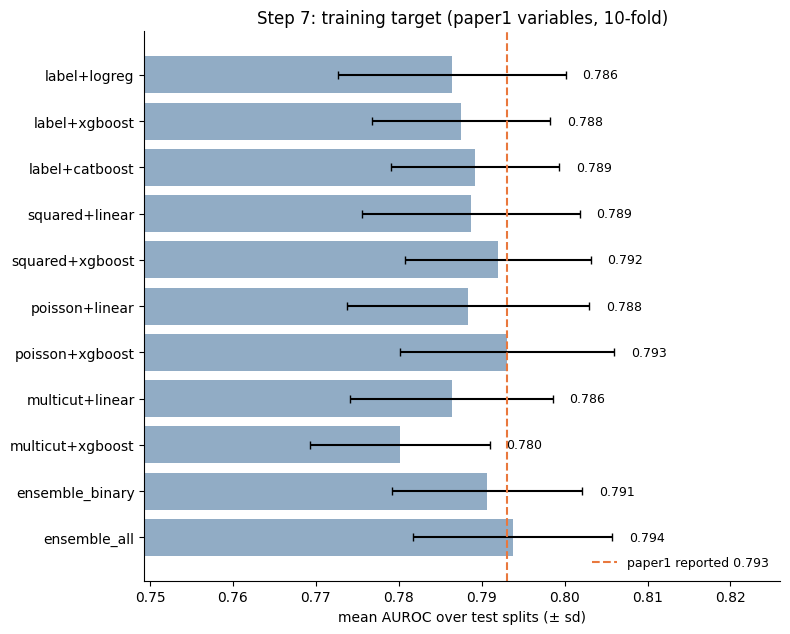

In [5]:
met = pd.read_csv(OUT / "metrics.csv")
order = ["label+logreg", "label+xgboost", "label+catboost", "squared+linear", "squared+xgboost",
         "poisson+linear", "poisson+xgboost", "multicut+linear", "multicut+xgboost", "ensemble_binary", "ensemble_all"]
plots.mean_auroc_bars(plots.summarise(met, order=order), ref=0.793, ref_label="paper1 reported 0.793",
                      title="Step 7: training target (paper1 variables, 10-fold)")
plots.show()